# Notatnik 08b — strojenie hiperparametrów LPPLS + ML (walk-forward)
Porównanie XGBoost, LightGBM, CatBoost, regresji logistycznej i drzewa decyzyjnego.
Dla każdego algorytmu trzy zestawy cech: Price-only, LPPLS-only, Price+LPPLS.
Cechy są obliczane wyłącznie z danych z dnia t lub wcześniejszych.
Przed każdą granicą kalibracyjną i testową usuwamy etykiety z przyszłości.
Domyślnie tylko spadek >=10% / 60 dni; RUN_ALL_NINE=True uruchamia 9 konfiguracji.

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, roc_auc_score,
                             average_precision_score, f1_score)

ROOT = Path('.')
OUT = ROOT / 'wyniki_tuning_08b'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
TEST_YEARS = [2021, 2022, 2023, 2024]
RUN_ALL_NINE = True
N_SEARCH_ITER = 20  # na test: 3 lub 5; do finalnego eksperymentu: 20–40
TARGET_CONFIGS = ([(d, h) for h in (30, 45, 60) for d in (10, 15, 20)]
                  if RUN_ALL_NINE else [(10, 60)])
THRESHOLDS = np.round(np.arange(0.10, 0.91, 0.05), 2)
MODEL_NAMES = ['LogisticRegression', 'DecisionTree', 'XGBoost', 'LightGBM', 'CatBoost']
print('Konfiguracje:', TARGET_CONFIGS)
print('Warianty w Randomized Search:', N_SEARCH_ITER)

Konfiguracje: [(10, 30), (15, 30), (20, 30), (10, 45), (15, 45), (20, 45), (10, 60), (15, 60), (20, 60)]
Warianty w Randomized Search: 20


## 1. Wczytaj zbiór z notatnika 07 i pełne dopasowania LPPLS
Wymagane pliki:
- `wyniki_future_drop_07/lppls_future_drop_dataset.csv` (lub w bieżącym folderze),
- `lppls_rolling_results.csv` (wszystkie okna, nie tylko zaakceptowane).
Jeśli brakuje pierwszego pliku, wykonaj najpierw notatnik 07 na rzeczywistych cenach BTC.

In [4]:
def find_file(candidates):
    for path in map(Path, candidates):
        if path.exists():
            return path
    raise FileNotFoundError('Nie znaleziono pliku. Sprawdź ścieżki: ' + ', '.join(map(str, candidates)))

file07 = find_file([
    ROOT / 'wyniki_future_drop_07' / 'lppls_future_drop_dataset.csv',
    ROOT / 'lppls_future_drop_dataset.csv'
])
filefits = find_file([
    ROOT / 'lppls_rolling_results.csv',
    ROOT / 'lppls_rolling_results_z_etykietami_baniek.csv'
])

base = pd.read_csv(file07)
base['date'] = pd.to_datetime(base['date'], utc=True).dt.tz_convert(None).dt.normalize()
base = base.sort_values('date').reset_index(drop=True)
for col in ['price', 'confidence', 'n_accepted', 'n_all']:
    base[col] = pd.to_numeric(base[col], errors='raise')
assert base.date.is_unique and base.date.is_monotonic_increasing
assert base.price.notna().all() and base.price.gt(0).all()
assert base.confidence.between(0, 1).all()
assert base.date.diff().dropna().eq(pd.Timedelta(days=1)).all(), 'Brakuje dni w zbiorze 07'

for drop, horizon in TARGET_CONFIGS:
    y_col, e_col = f'drop_{drop}_h{horizon}', f'label_end_h{horizon}'
    assert y_col in base.columns and e_col in base.columns, f'Brak {y_col} lub {e_col}'
    base[y_col] = pd.to_numeric(base[y_col], errors='coerce')
    base[e_col] = pd.to_datetime(base[e_col], errors='coerce')
    valid = base[e_col].notna()
    assert (base.loc[valid, e_col] == base.loc[valid, 'date'] + pd.Timedelta(days=horizon)).all()
    assert base[y_col].isna().equals(~valid)

fits = pd.read_csv(filefits, parse_dates=['win_end'])
print('Dane z 07:', base.shape, '| Wszystkie okna:', fits.shape)

Dane z 07: (3624, 20) | Wszystkie okna: (107240, 20)


## 2. Cechy cenowe: wyłącznie przeszłość i dzień prognozy
Nie przekazujemy modelom bieżącej ceny bezwzględnej, etykiet literaturowych
ani kolumn future_drop. Retrospektywne etykiety służą wyłącznie do oceny.

In [5]:
data = base.copy()
price = data['price']
log_return = np.log(price / price.shift(1))

data['ret_1d'] = log_return
for n in (7, 14, 30, 60):
    data[f'momentum_{n}d'] = np.log(price / price.shift(n))
for n in (7, 30, 60):
    data[f'volatility_{n}d'] = log_return.rolling(n, min_periods=n).std()
for n in (30, 90):
    data[f'drawdown_{n}d'] = price / price.rolling(n, min_periods=n).max() - 1

PRICE_FEATURES = ([ 'ret_1d' ]
    + [f'momentum_{n}d' for n in (7, 14, 30, 60)]
    + [f'volatility_{n}d' for n in (7, 30, 60)]
    + [f'drawdown_{n}d' for n in (30, 90)])

## 3. Cechy LPPLS na poziomie dnia
Stosujemy te same kryteria co wcześniej: 0<m<1, 6<=w<=13, B<0,
0<t_gap<=40 dni, R2>0.90. Agregujemy parametry zaakceptowanych okien,
bez bezwzględnego tc i A, które mogą identyfikować poziom cen / okres.
Dni bez zaakceptowanych okien ZOSTAJĄ w próbie; mediany wtedy są NaN
i zostaną uzupełnione tylko na podstawie danych treningowych.

In [6]:
for col in ('m','w','B','C','r2','tc','n'):
    fits[col] = pd.to_numeric(fits[col], errors='coerce')

ok_flag = fits['ok'].astype(str).str.lower().isin(['true', '1', 'yes'])
fits['t_gap'] = fits['tc'] - fits['win_end'].map(lambda dt: dt.toordinal())
fits['accepted'] = (
    ok_flag & fits['m'].gt(0) & fits['m'].lt(1)
    & fits['w'].between(6, 13)
    & fits['B'].lt(0) & fits['t_gap'].gt(0) & fits['t_gap'].le(40)
    & fits['r2'].gt(0.90)
)

# Zweryfikuj zgodność liczebności z notatnikiem 07.
recount = fits.groupby('win_end')['accepted'].sum().rename('recomputed')
check = data[['date', 'n_accepted']].merge(recount, left_on='date', right_index=True, how='left')
assert check['recomputed'].notna().all(), 'Dni bez wyliczonych okien LPPLS.'
assert (check['n_accepted'] == check['recomputed']).all(), (
    'Zbiór z 07 i dopasowania LPPLS pochodzą z innych uruchomień/filtrów.'
)

accepted = fits.loc[fits['accepted']]
agg = accepted.groupby('win_end').agg(
    lppls_m=('m', 'median'),
    lppls_w=('w', 'median'),
    lppls_tgap=('t_gap', 'median'),
    lppls_r2=('r2', 'median'),
    lppls_B=('B', 'median'),
    lppls_C=('C', 'median'),
    lppls_window_n=('n', 'median'),
    lppls_tgap_std=('t_gap', 'std'),
)

data = data.merge(agg, left_on='date', right_index=True, how='left', validate='one_to_one')
data = data.rename(columns={'confidence':'lppls_ci', 'n_accepted':'lppls_n_accepted'})
LPPLS_FEATURES = ['lppls_ci', 'lppls_n_accepted'] + list(agg.columns)
FEATURE_GROUPS = {
    'Price-only': PRICE_FEATURES,
    'LPPLS-only': LPPLS_FEATURES,
    'Price+LPPLS': PRICE_FEATURES + LPPLS_FEATURES,
}

# Zapis jednego zbioru cech; NIE wybieraj zmiennych wejściowych spośród kolumn target.
data.to_csv(OUT / '01_cechy_dzienne.csv', index=False)
print('Zaakceptowane okna:', len(accepted))
print('Cechy cenowe:', PRICE_FEATURES)
print('Cechy LPPLS:', LPPLS_FEATURES)
display(data[['date','lppls_ci','lppls_n_accepted','lppls_tgap']].head())

Zaakceptowane okna: 1518
Cechy cenowe: ['ret_1d', 'momentum_7d', 'momentum_14d', 'momentum_30d', 'momentum_60d', 'volatility_7d', 'volatility_30d', 'volatility_60d', 'drawdown_30d', 'drawdown_90d']
Cechy LPPLS: ['lppls_ci', 'lppls_n_accepted', 'lppls_m', 'lppls_w', 'lppls_tgap', 'lppls_r2', 'lppls_B', 'lppls_C', 'lppls_window_n', 'lppls_tgap_std']


,date,lppls_ci,lppls_n_accepted,lppls_tgap
0,2015-01-30,0.0,0,NaN
1,2015-01-31,0.0,0,NaN
2,2015-02-01,0.0,0,NaN
3,2015-02-02,0.0,0,NaN
4,2015-02-03,0.0,0,NaN


## 4. Przestrzenie hiperparametrów i metryki
Ograniczone zakresy zapobiegają niepotrzebnemu przeszukiwaniu ogromnej przestrzeni.
Wszelkie parametry wybieramy bez zaglądania do roku testowego.

In [7]:
import json
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import roc_auc_score, average_precision_score

SEARCH_SPACE = {
    'LogisticRegression': {
        'C': [0.01, 0.1, 0.3, 1.0, 3.0, 10.0],
        'class_weight': [None, 'balanced']
    },
    'DecisionTree': {
        'max_depth': [2, 3, 4, 6, 8],
        'min_samples_leaf': [15, 30, 60, 100],
        'min_samples_split': [10, 30, 60],
        'class_weight': [None, 'balanced']
    },
    'XGBoost': {
        'n_estimators': [100, 200, 350],
        'max_depth': [2, 3, 5],
        'learning_rate': [0.02, 0.05, 0.10],
        'subsample': [0.7, 0.9, 1.0],
        'colsample_bytree': [0.7, 1.0],
        'min_child_weight': [1, 5, 15],
        'reg_lambda': [1, 5, 10]
    },
    'LightGBM': {
        'n_estimators': [100, 200, 350],
        'learning_rate': [0.02, 0.05, 0.10],
        'num_leaves': [7, 15, 31],
        'min_child_samples': [20, 40, 80],
        'colsample_bytree': [0.7, 1.0],
        'subsample': [0.8, 1.0],
    },
    'CatBoost': {
        'iterations': [100, 200, 350],
        'depth': [3, 4, 6],
        'learning_rate': [0.02, 0.05, 0.10],
        'l2_leaf_reg': [3, 10, 30],
    },
}

def make_model(name, params):
    if name == 'LogisticRegression':
        return LogisticRegression(max_iter=2500, random_state=SEED, **params)
    if name == 'DecisionTree':
        return DecisionTreeClassifier(random_state=SEED, **params)
    if name == 'XGBoost':
        from xgboost import XGBClassifier
        return XGBClassifier(random_state=SEED, n_jobs=2, tree_method='hist',
                             eval_metric='logloss', **params)
    if name == 'LightGBM':
        from lightgbm import LGBMClassifier
        return LGBMClassifier(random_state=SEED, n_jobs=2, verbosity=-1, **params)
    if name == 'CatBoost':
        from catboost import CatBoostClassifier
        return CatBoostClassifier(random_seed=SEED, thread_count=2,
                                  verbose=False, allow_writing_files=False, **params)
    raise ValueError(name)


def prepare_arrays(x_train, x_pred, name):
    imputer = SimpleImputer(strategy='median', add_indicator=True,
                            keep_empty_features=True)
    train_mat = imputer.fit_transform(x_train)
    pred_mat = imputer.transform(x_pred)
    if name == 'LogisticRegression':
        scaler = StandardScaler()
        train_mat = scaler.fit_transform(train_mat)
        pred_mat = scaler.transform(pred_mat)
    return train_mat, pred_mat


def proba_fit_predict(name, params, train, val, features, target):
    Xtr, Xva = prepare_arrays(train[features], val[features], name)
    model = make_model(name, params)
    model.fit(Xtr, train[target].to_numpy(dtype=int))
    return model.predict_proba(Xva)[:, 1]


def evaluate(y, pred, score):
    y = np.asarray(y, dtype=int)
    pred = np.asarray(pred, dtype=int)
    score = np.asarray(score, dtype=float)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(n=len(y), positives=int(tp+fn), TP=int(tp), FP=int(fp),
                FN=int(fn), TN=int(tn), alarm_days=int(pred.sum()),
                precision=(tp/(tp+fp) if tp+fp else np.nan),
                recall=(tp/(tp+fn) if tp+fn else np.nan),
                specificity=(tn/(tn+fp) if tn+fp else np.nan),
                f1=(2*tp/(2*tp+fp+fn) if (tp+fn) else np.nan),
                roc_auc=(roc_auc_score(y, score) if len(np.unique(y))==2 else np.nan),
                avg_precision=(average_precision_score(y, score) if (tp+fn) else np.nan))


def choose_threshold(y, prob):
    y = np.asarray(y, dtype=int)
    if len(np.unique(y)) < 2:
        return 0.5, 'fallback_one_class'
    scores=[]
    for t in THRESHOLDS:
        pred=(prob>=t).astype(int)
        f1=f1_score(y, pred, zero_division=0)
        scores.append((f1, -int(pred.sum()), float(t)))
    best=max(scores, key=lambda x: (x[0], x[1], x[2]))
    return best[2], 'F1_threshold_validation'

## 5. Dobór hiperparametrów przez dwa WEWNĘTRZNE podziały chronologiczne
Dla roku testowego Y:
- walidacje parametrów: Y-3 oraz Y-2
- walidacja progu: Y-1
- test: Y
Trening w każdej iteracji używa tylko etykiet znanych przed początkiem walidacji.
Wynik wyszukiwania to średni Average Precision z dostępnych foldów wewnętrznych.

In [8]:
def search_params(sample, year, model_name, group_name, features, target, end_col):
    threshold_start = pd.Timestamp(f'{year-1}-01-01')
    candidates = list(ParameterSampler(
        SEARCH_SPACE[model_name], n_iter=N_SEARCH_ITER,
        random_state=SEED + year + MODEL_NAMES.index(model_name)
    ))
    trials=[]
    for idx, params in enumerate(candidates):
        scores=[]
        for val_year in (year-3, year-2):
            val_start=pd.Timestamp(f'{val_year}-01-01')
            val_stop=pd.Timestamp(f'{val_year+1}-01-01')
            train=sample.loc[(sample.date<val_start) & (sample[end_col]<val_start)]
            val=sample.loc[(sample.date>=val_start) & (sample.date<val_stop)
                           & (sample[end_col]<threshold_start)]
            if train.empty or val.empty:
                continue
            if train[target].nunique()<2 or val[target].nunique()<2:
                continue
            assert train[end_col].max() < val.date.min()
            pr=proba_fit_predict(model_name, params, train, val, features, target)
            scores.append(average_precision_score(val[target].to_numpy(dtype=int),pr))
        trials.append(dict(
            year=year, model=model_name, feature_group=group_name,
            trial=idx+1, mean_AP=float(np.mean(scores)) if scores else np.nan,
            n_inner_folds=len(scores), params=json.dumps(params, sort_keys=True),
        ))
    valid=[t for t in trials if np.isfinite(t['mean_AP'])]
    if not valid:
        return None, trials
    best=max(valid, key=lambda r:(r['mean_AP'],r['n_inner_folds']))
    best['selected']=True
    for r in trials:
        r.setdefault('selected',False)
    return json.loads(best['params']), trials

## 6. Właściwy eksperyment: parametry -> próg -> test
Aby nie zmieniać kalibracji po wyborze progu, testujemy dokładnie model
wytrenowany przed rokiem walidacji progu; nie dokonujemy refitu na roku progu.
To konserwatywne rozwiązanie, które pozwala porównać modele bez ryzyka
przesunięcia rozkładu prawdopodobieństw po ponownym treningu.

In [9]:
search_rows=[]; fold_rows=[]; prediction_rows=[]; selected_rows=[]
for drop,horizon in TARGET_CONFIGS:
    target=f'drop_{drop}_h{horizon}'
    end_col=f'label_end_h{horizon}'
    sample=data.loc[data[target].notna()].copy()
    sample[end_col]=pd.to_datetime(sample[end_col]); sample[target]=sample[target].astype(int)
    for year in TEST_YEARS:
        threshold_start=pd.Timestamp(f'{year-1}-01-01')
        test_start=pd.Timestamp(f'{year}-01-01')
        test_stop=pd.Timestamp(f'{year+1}-01-01')
        train_for_threshold=sample.loc[(sample.date<threshold_start)
                                      & (sample[end_col]<threshold_start)]
        threshold_val=sample.loc[(sample.date>=threshold_start)
                                  & (sample.date<test_start)
                                  & (sample[end_col]<test_start)]
        test=sample.loc[(sample.date>=test_start)&(sample.date<test_stop)]
        if any(d.empty for d in (train_for_threshold, threshold_val, test)):
            warnings.warn(f'Pusty okres dla {drop}/{horizon}, rok {year}'); continue
        if train_for_threshold[target].nunique()<2:
            warnings.warn(f'Brak dwóch klas w treningu {drop}/{horizon}, rok {year}'); continue
        assert train_for_threshold[end_col].max()<threshold_val.date.min()
        assert threshold_val[end_col].max()<test.date.min()
        print(f'Test {year} | target {drop}%/{horizon}d | train {len(train_for_threshold)}, threshold-val {len(threshold_val)}, test {len(test)}')
        y_test=test[target].to_numpy(dtype=int)

        baseline={
            'Always-positive': (np.ones(len(test), dtype=int), np.ones(len(test))),
            'CI > 0':((test.lppls_ci.to_numpy()>0).astype(int),test.lppls_ci.to_numpy()),
            'CI > 0.05':((test.lppls_ci.to_numpy()>0.05).astype(int),test.lppls_ci.to_numpy())
        }
        for name,(pred,score) in baseline.items():
            fold_rows.append(dict(year=year, drop_pct=drop,horizon=horizon,
                model=name, feature_group='Baseline', selected_threshold=np.nan,
                params='{}',**evaluate(y_test,pred,score)))
            prediction_rows.append(pd.DataFrame(dict(date=test.date.to_numpy(),year=year,
                drop_pct=drop,horizon=horizon, model=name,feature_group='Baseline',
                y_true=y_test, y_pred=pred, score=score)))

        for group, features in FEATURE_GROUPS.items():
            for name in MODEL_NAMES:
                params, trials=search_params(sample,year,name,group,features,target,end_col)
                for r in trials:
                    search_rows.append(dict(drop_pct=drop,horizon=horizon,**r))
                if params is None:
                    warnings.warn(f'Brak poprawnej wewnętrznej walidacji dla {year}/{name}/{group}')
                    continue
                val_score=proba_fit_predict(name,params,train_for_threshold,threshold_val,features,target)
                threshold,rule=choose_threshold(threshold_val[target].to_numpy(dtype=int),val_score)
                test_score=proba_fit_predict(name,params,train_for_threshold,test,features,target)
                pred=(test_score>=threshold).astype(int)
                params_json=json.dumps(params,sort_keys=True)
                selected_rows.append(dict(year=year,drop_pct=drop,horizon=horizon,
                    model=name,feature_group=group, params=params_json,
                    threshold=threshold,threshold_rule=rule))
                fold_rows.append(dict(year=year,drop_pct=drop,horizon=horizon,
                    model=name,feature_group=group,selected_threshold=threshold,
                    params=params_json,**evaluate(y_test,pred,test_score)))
                prediction_rows.append(pd.DataFrame(dict(date=test.date.to_numpy(),year=year,
                    drop_pct=drop,horizon=horizon,model=name,feature_group=group,
                    y_true=y_test,y_pred=pred,score=test_score)))

folds=pd.DataFrame(fold_rows)
preds=pd.concat(prediction_rows,ignore_index=True)
search_results=pd.DataFrame(search_rows)
selected=pd.DataFrame(selected_rows)
search_results.to_csv(OUT/'08b_01_wyniki_search.csv', index=False)
selected.to_csv(OUT/'08b_02_wybrane_hiperparametry.csv', index=False)
folds.to_csv(OUT/'08b_03_wyniki_roczne.csv', index=False)
preds.to_csv(OUT/'08b_04_predykcje_OOS.csv', index=False)
print('Zakończono strojenie. Liczba eksperymentów:',len(folds))
display(selected.head(10))

Test 2021 | target 10%/30d | train 1767, threshold-val 336, test 365


C:\Users\cynar\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 12 is smaller than n_iter=20. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
C:\Users\cynar\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 12 is smaller than n_iter=20. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
C:\Users\cynar\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 12 is smaller than n_iter=20. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Test 2022 | target 10%/30d | train 2133, threshold-val 335, test 365


C:\Users\cynar\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 12 is smaller than n_iter=20. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
C:\Users\cynar\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 12 is smaller than n_iter=20. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
C:\Users\cynar\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 12 is smaller than n_iter=20. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Test 2023 | target 10%/30d | train 2498, threshold-val 335, test 365


C:\Users\cynar\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 12 is smaller than n_iter=20. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
C:\Users\cynar\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 12 is smaller than n_iter=20. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
C:\Users\cynar\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 12 is smaller than n_iter=20. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


... (64 outputs left out)

Test 2024 | target 20%/60d | train 2833, threshold-val 305, test 306


C:\Users\cynar\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 12 is smaller than n_iter=20. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
C:\Users\cynar\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 12 is smaller than n_iter=20. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
C:\Users\cynar\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 12 is smaller than n_iter=20. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Zakończono strojenie. Liczba eksperymentów: 648


,year,drop_pct,horizon,model,feature_group,params,threshold,threshold_rule
0,2021,10,30,LogisticRegression,Price-only,"{""C"": 0.01, ""class_weight"": null}",0.25,F1_threshold_validation
1,2021,10,30,DecisionTree,Price-only,"{""class_weight"": null, ""max_depth"": 4, ""min_sa...",0.20,F1_threshold_validation
2,2021,10,30,XGBoost,Price-only,"{""colsample_bytree"": 0.7, ""learning_rate"": 0.0...",0.20,F1_threshold_validation
3,2021,10,30,LightGBM,Price-only,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.0...",0.20,F1_threshold_validation
4,2021,10,30,CatBoost,Price-only,"{""depth"": 4, ""iterations"": 100, ""l2_leaf_reg"":...",0.20,F1_threshold_validation
5,2021,10,30,LogisticRegression,LPPLS-only,"{""C"": 0.01, ""class_weight"": ""balanced""}",0.60,F1_threshold_validation
6,2021,10,30,DecisionTree,LPPLS-only,"{""class_weight"": null, ""max_depth"": 4, ""min_sa...",0.15,F1_threshold_validation
7,2021,10,30,XGBoost,LPPLS-only,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.0...",0.35,F1_threshold_validation
8,2021,10,30,LightGBM,LPPLS-only,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.0...",0.40,F1_threshold_validation
9,2021,10,30,CatBoost,LPPLS-only,"{""depth"": 3, ""iterations"": 100, ""l2_leaf_reg"":...",0.35,F1_threshold_validation


## 7. Łączne wyniki OOS + efekt LPPLS dla danego algorytmu
Nie wolno uśredniać ROC-AUC z lat; liczymy na połączonych prognozach OOS.

,model,feature_group,precision,recall,f1,specificity,roc_auc,avg_precision,alarm_days,FP
0,Always-positive,Baseline,0.400,1.000,0.571,0.000,0.500,0.400,1431,859
1,CI > 0,Baseline,0.369,0.138,0.201,0.843,0.494,0.414,214,135
2,CI > 0.05,Baseline,0.484,0.103,0.170,0.927,0.494,0.414,122,63
12,CatBoost,LPPLS-only,0.344,0.694,0.460,0.118,0.479,0.402,1155,758
9,DecisionTree,LPPLS-only,0.406,0.998,0.577,0.027,0.473,0.409,1407,836
11,LightGBM,LPPLS-only,0.340,0.659,0.448,0.147,0.483,0.412,1110,733
8,LogisticRegression,LPPLS-only,0.344,0.670,0.454,0.149,0.490,0.424,1114,731
10,XGBoost,LPPLS-only,0.338,0.659,0.447,0.140,0.469,0.405,1116,739
17,CatBoost,Price+LPPLS,0.401,0.774,0.528,0.229,0.498,0.391,1105,662
14,DecisionTree,Price+LPPLS,0.408,0.825,0.546,0.201,0.461,0.386,1158,686


,model,delta_F1,delta_AvgPrecision,delta_ROC_AUC
0,CatBoost,0.004,0.012,0.002
1,DecisionTree,0.012,-0.012,-0.039
2,LightGBM,-0.046,0.029,0.011
3,LogisticRegression,-0.002,0.011,-0.016
4,XGBoost,0.030,0.018,0.011


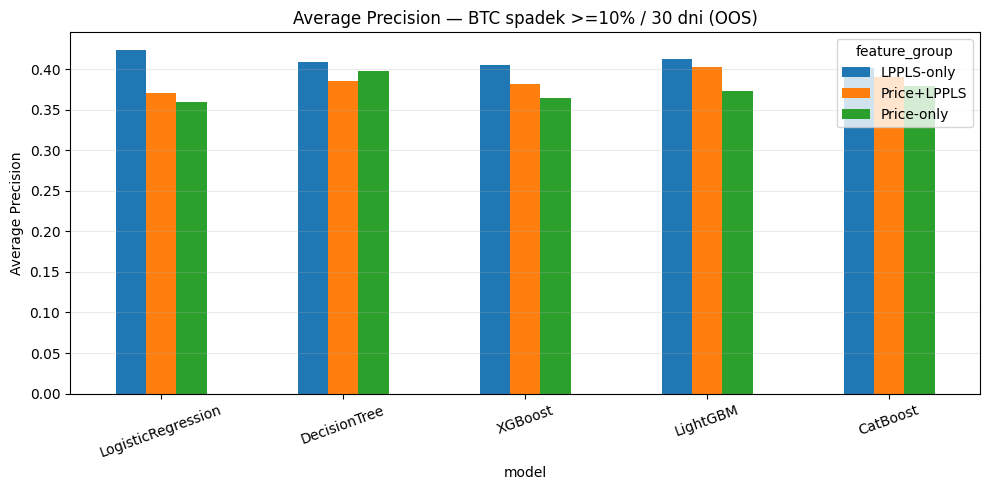

,model,feature_group,precision,recall,f1,specificity,roc_auc,avg_precision,alarm_days,FP
18,Always-positive,Baseline,0.239,1.000,0.386,0.000,0.500,0.239,1431,1089
19,CI > 0,Baseline,0.206,0.129,0.158,0.844,0.489,0.246,214,170
20,CI > 0.05,Baseline,0.270,0.096,0.142,0.918,0.489,0.246,122,89
30,CatBoost,LPPLS-only,0.238,0.997,0.385,0.000,0.427,0.233,1430,1089
27,DecisionTree,LPPLS-only,0.241,0.997,0.388,0.012,0.415,0.234,1417,1076
29,LightGBM,LPPLS-only,0.236,0.942,0.377,0.042,0.414,0.231,1365,1043
26,LogisticRegression,LPPLS-only,0.241,0.994,0.388,0.018,0.300,0.186,1409,1069
28,XGBoost,LPPLS-only,0.242,0.997,0.389,0.017,0.430,0.240,1412,1071
35,CatBoost,Price+LPPLS,0.250,0.877,0.389,0.174,0.474,0.208,1200,900
32,DecisionTree,Price+LPPLS,0.282,0.757,0.411,0.395,0.569,0.285,918,659


,model,delta_F1,delta_AvgPrecision,delta_ROC_AUC
0,CatBoost,0.074,-0.015,-0.040
1,DecisionTree,0.023,0.004,0.008
2,LightGBM,0.058,-0.001,0.005
3,LogisticRegression,0.003,-0.002,0.005
4,XGBoost,-0.065,-0.005,-0.038


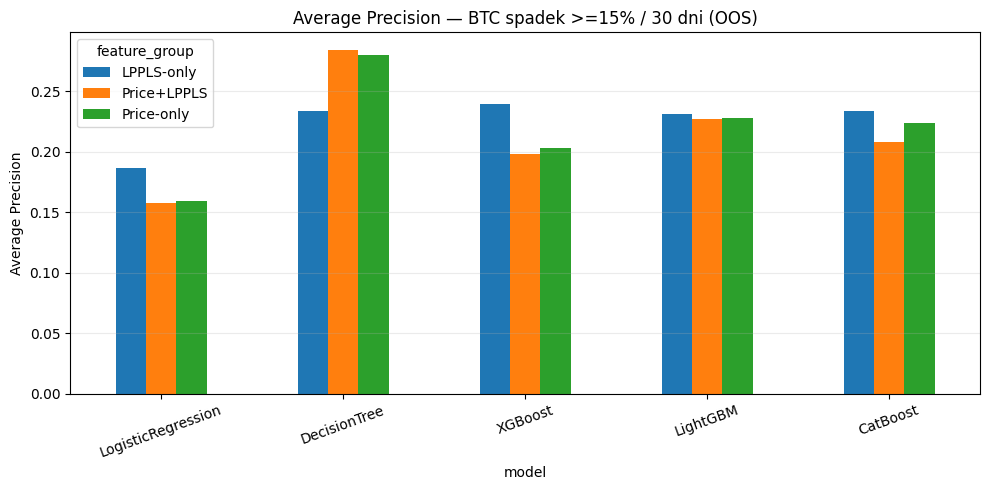

,model,feature_group,precision,recall,f1,specificity,roc_auc,avg_precision,alarm_days,FP
36,Always-positive,Baseline,0.114,1.000,0.205,0.000,0.500,0.114,1431,1268
37,CI > 0,Baseline,0.103,0.135,0.117,0.849,0.494,0.125,214,192
38,CI > 0.05,Baseline,0.123,0.092,0.105,0.916,0.494,0.125,122,107
48,CatBoost,LPPLS-only,0.137,0.890,0.238,0.280,0.256,0.093,1058,913
45,DecisionTree,LPPLS-only,0.147,0.957,0.254,0.284,0.498,0.165,1064,908
47,LightGBM,LPPLS-only,0.135,0.865,0.233,0.286,0.426,0.130,1046,905
44,LogisticRegression,LPPLS-only,0.145,0.939,0.251,0.289,0.605,0.171,1055,902
46,XGBoost,LPPLS-only,0.138,0.890,0.239,0.285,0.544,0.150,1052,907
53,CatBoost,Price+LPPLS,0.121,0.472,0.193,0.559,0.382,0.087,636,559
50,DecisionTree,Price+LPPLS,0.151,0.583,0.240,0.580,0.486,0.152,628,533


,model,delta_F1,delta_AvgPrecision,delta_ROC_AUC
0,CatBoost,-0.043,0.000,-0.013
1,DecisionTree,-0.003,0.038,0.054
2,LightGBM,-0.067,0.007,0.040
3,LogisticRegression,0.038,0.045,0.343
4,XGBoost,-0.006,0.001,0.002


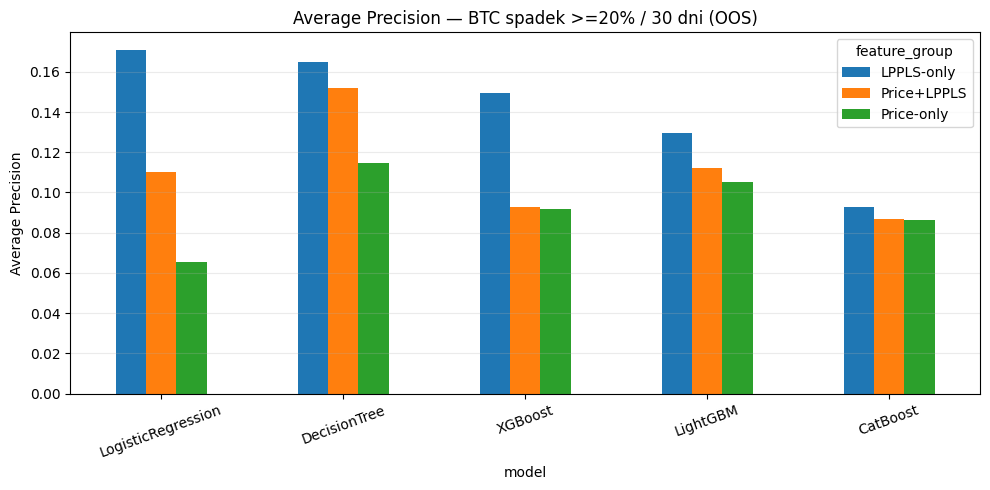

,model,feature_group,precision,recall,f1,specificity,roc_auc,avg_precision,alarm_days,FP
54,Always-positive,Baseline,0.492,1.000,0.660,0.000,0.500,0.492,1416,719
55,CI > 0,Baseline,0.529,0.158,0.243,0.864,0.512,0.507,208,98
56,CI > 0.05,Baseline,0.566,0.099,0.168,0.926,0.512,0.507,122,53
66,CatBoost,LPPLS-only,0.438,0.706,0.541,0.122,0.496,0.503,1123,631
63,DecisionTree,LPPLS-only,0.437,0.709,0.541,0.115,0.378,0.444,1130,636
65,LightGBM,LPPLS-only,0.438,0.707,0.541,0.121,0.493,0.503,1125,632
62,LogisticRegression,LPPLS-only,0.441,0.716,0.546,0.120,0.570,0.538,1132,633
64,XGBoost,LPPLS-only,0.440,0.710,0.544,0.125,0.500,0.508,1124,629
71,CatBoost,Price+LPPLS,0.492,0.878,0.630,0.120,0.471,0.465,1245,633
68,DecisionTree,Price+LPPLS,0.495,0.845,0.625,0.166,0.515,0.513,1189,600


,model,delta_F1,delta_AvgPrecision,delta_ROC_AUC
0,CatBoost,-0.016,0.039,0.039
1,DecisionTree,0.004,0.002,-0.007
2,LightGBM,0.006,0.029,0.008
3,LogisticRegression,0.003,0.008,0.013
4,XGBoost,0.005,0.006,0.006


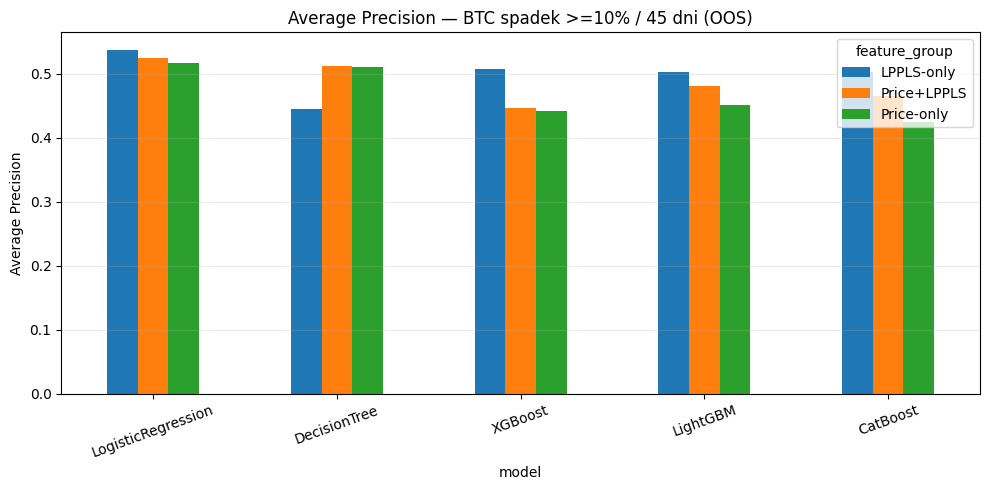

,model,feature_group,precision,recall,f1,specificity,roc_auc,avg_precision,alarm_days,FP
72,Always-positive,Baseline,0.321,1.000,0.486,0.000,0.500,0.321,1416,962
73,CI > 0,Baseline,0.298,0.137,0.187,0.848,0.493,0.323,208,146
74,CI > 0.05,Baseline,0.336,0.090,0.142,0.916,0.493,0.323,122,81
84,CatBoost,LPPLS-only,0.262,0.634,0.370,0.155,0.431,0.325,1101,813
81,DecisionTree,LPPLS-only,0.267,0.639,0.376,0.172,0.440,0.323,1087,797
83,LightGBM,LPPLS-only,0.260,0.630,0.368,0.154,0.432,0.320,1100,814
80,LogisticRegression,LPPLS-only,0.320,0.993,0.484,0.004,0.509,0.390,1409,958
82,XGBoost,LPPLS-only,0.273,0.667,0.387,0.161,0.453,0.326,1110,807
89,CatBoost,Price+LPPLS,0.267,0.456,0.337,0.411,0.456,0.292,774,567
86,DecisionTree,Price+LPPLS,0.416,0.927,0.574,0.386,0.531,0.340,1012,591


,model,delta_F1,delta_AvgPrecision,delta_ROC_AUC
0,CatBoost,-0.146,0.010,-0.009
1,DecisionTree,0.095,0.017,0.045
2,LightGBM,-0.090,-0.005,-0.023
3,LogisticRegression,0.031,0.059,0.148
4,XGBoost,-0.002,-0.006,-0.001


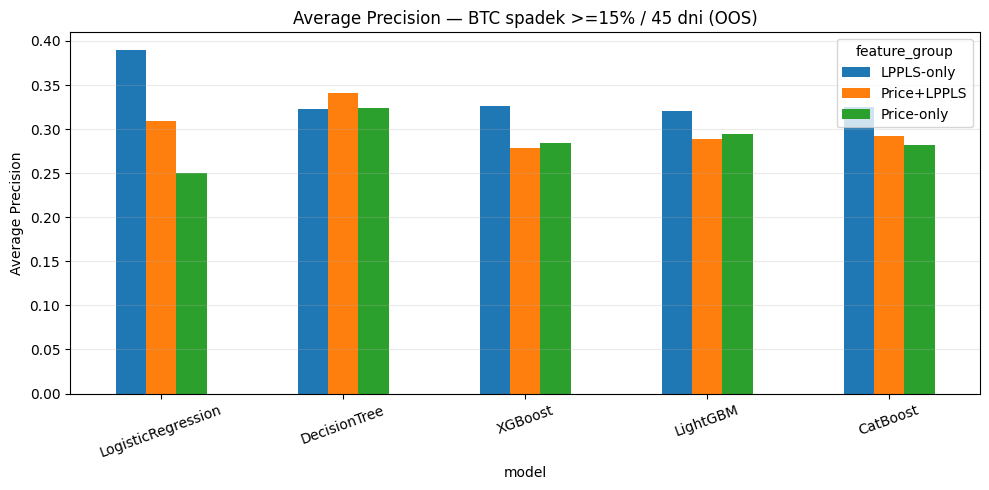

,model,feature_group,precision,recall,f1,specificity,roc_auc,avg_precision,alarm_days,FP
90,Always-positive,Baseline,0.180,1.000,0.305,0.000,0.500,0.180,1416,1161
91,CI > 0,Baseline,0.163,0.133,0.147,0.850,0.495,0.192,208,174
92,CI > 0.05,Baseline,0.205,0.098,0.133,0.916,0.495,0.192,122,97
102,CatBoost,LPPLS-only,0.158,0.463,0.236,0.458,0.236,0.143,747,629
99,DecisionTree,LPPLS-only,0.161,0.447,0.237,0.488,0.536,0.252,709,595
101,LightGBM,LPPLS-only,0.162,0.475,0.242,0.463,0.385,0.170,745,624
98,LogisticRegression,LPPLS-only,0.164,0.494,0.247,0.448,0.762,0.327,767,641
100,XGBoost,LPPLS-only,0.167,0.490,0.249,0.463,0.386,0.170,748,623
107,CatBoost,Price+LPPLS,0.231,0.886,0.367,0.353,0.442,0.147,977,751
104,DecisionTree,Price+LPPLS,0.175,0.824,0.289,0.149,0.494,0.189,1198,988


,model,delta_F1,delta_AvgPrecision,delta_ROC_AUC
0,CatBoost,-0.003,-0.006,-0.025
1,DecisionTree,-0.096,-0.055,-0.120
2,LightGBM,-0.216,-0.003,-0.012
3,LogisticRegression,-0.017,0.000,0.008
4,XGBoost,-0.017,0.012,0.062


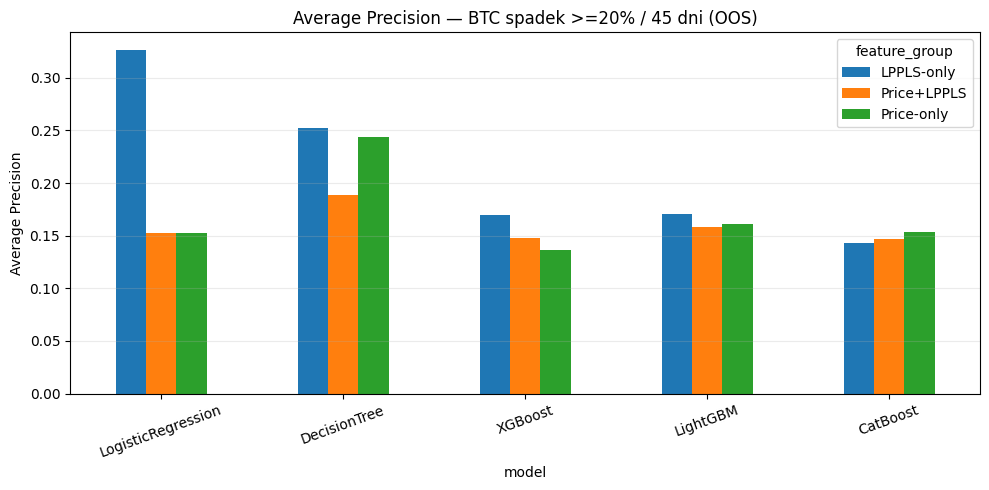

,model,feature_group,precision,recall,f1,specificity,roc_auc,avg_precision,alarm_days,FP
108,Always-positive,Baseline,0.545,1.000,0.706,0.000,0.500,0.545,1401,637
109,CI > 0,Baseline,0.605,0.154,0.246,0.879,0.518,0.567,195,77
110,CI > 0.05,Baseline,0.673,0.097,0.169,0.943,0.518,0.567,110,36
120,CatBoost,LPPLS-only,0.545,0.997,0.705,0.002,0.487,0.558,1398,636
117,DecisionTree,LPPLS-only,0.542,0.979,0.698,0.009,0.395,0.514,1379,631
119,LightGBM,LPPLS-only,0.545,0.992,0.703,0.005,0.482,0.549,1392,634
116,LogisticRegression,LPPLS-only,0.545,0.995,0.704,0.005,0.570,0.582,1394,634
118,XGBoost,LPPLS-only,0.545,0.999,0.705,0.000,0.480,0.547,1400,637
125,CatBoost,Price+LPPLS,0.544,0.963,0.695,0.030,0.467,0.498,1354,618
122,DecisionTree,Price+LPPLS,0.557,0.781,0.650,0.254,0.469,0.513,1072,475


,model,delta_F1,delta_AvgPrecision,delta_ROC_AUC
0,CatBoost,-0.001,0.015,0.022
1,DecisionTree,0.010,-0.007,-0.020
2,LightGBM,0.017,0.063,0.053
3,LogisticRegression,0.001,-0.005,-0.014
4,XGBoost,0.005,0.018,0.048


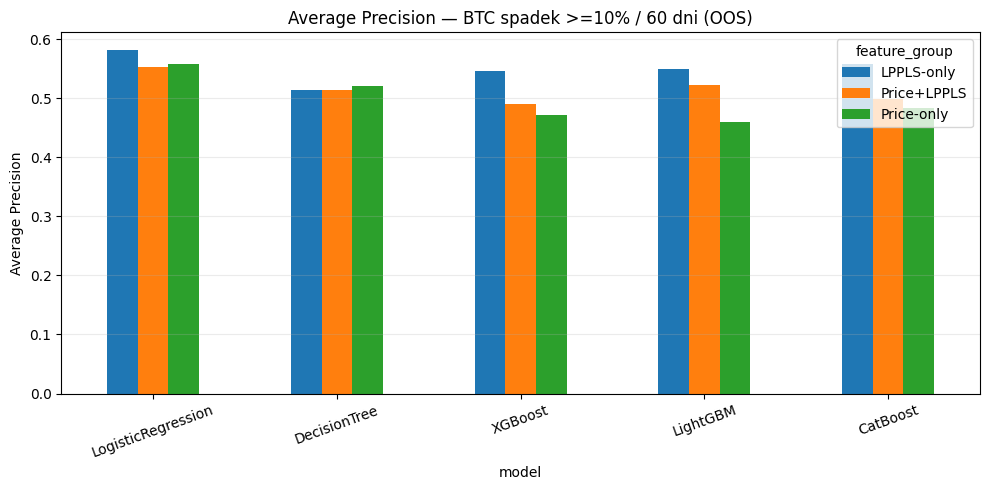

,model,feature_group,precision,recall,f1,specificity,roc_auc,avg_precision,alarm_days,FP
126,Always-positive,Baseline,0.385,1.000,0.556,0.000,0.500,0.385,1401,862
127,CI > 0,Baseline,0.390,0.141,0.207,0.862,0.503,0.396,195,119
128,CI > 0.05,Baseline,0.445,0.091,0.151,0.929,0.503,0.396,110,61
138,CatBoost,LPPLS-only,0.356,0.523,0.423,0.407,0.435,0.376,793,511
135,DecisionTree,LPPLS-only,0.383,0.976,0.550,0.019,0.330,0.349,1372,846
137,LightGBM,LPPLS-only,0.324,0.644,0.431,0.159,0.431,0.379,1072,725
134,LogisticRegression,LPPLS-only,0.383,0.981,0.550,0.009,0.367,0.347,1383,854
136,XGBoost,LPPLS-only,0.348,0.521,0.417,0.389,0.448,0.385,808,527
143,CatBoost,Price+LPPLS,0.384,0.842,0.528,0.157,0.451,0.344,1181,727
140,DecisionTree,Price+LPPLS,0.378,0.636,0.474,0.345,0.367,0.348,908,565


,model,delta_F1,delta_AvgPrecision,delta_ROC_AUC
0,CatBoost,-0.017,0.017,0.022
1,DecisionTree,0.060,-0.012,-0.047
2,LightGBM,0.013,0.006,0.054
3,LogisticRegression,0.002,-0.056,-0.114
4,XGBoost,0.021,0.034,0.042


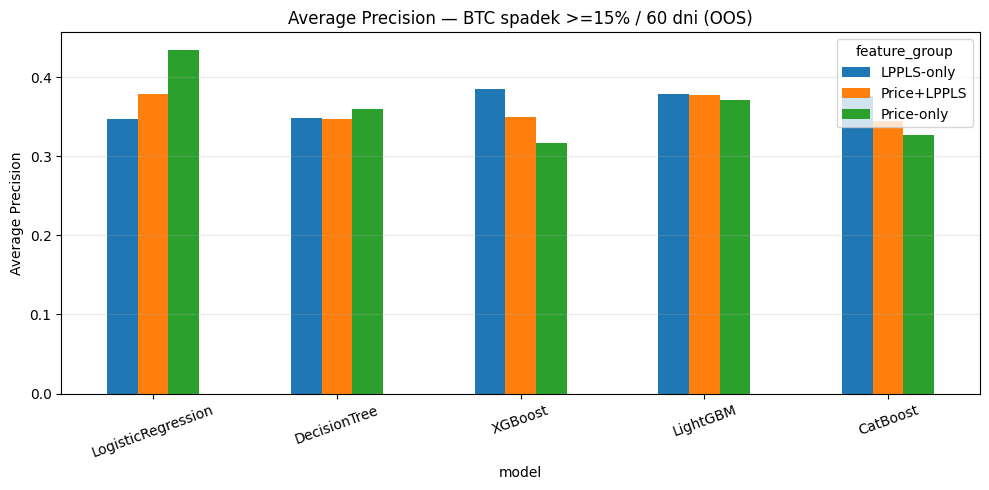

,model,feature_group,precision,recall,f1,specificity,roc_auc,avg_precision,alarm_days,FP
144,Always-positive,Baseline,0.230,1.000,0.374,0.000,0.500,0.230,1401,1079
145,CI > 0,Baseline,0.236,0.143,0.178,0.862,0.504,0.240,195,149
146,CI > 0.05,Baseline,0.264,0.090,0.134,0.925,0.504,0.240,110,81
156,CatBoost,LPPLS-only,0.268,0.857,0.408,0.301,0.389,0.217,1030,754
153,DecisionTree,LPPLS-only,0.196,0.435,0.271,0.469,0.542,0.267,713,573
155,LightGBM,LPPLS-only,0.205,0.444,0.280,0.485,0.407,0.224,699,556
152,LogisticRegression,LPPLS-only,0.224,0.941,0.362,0.028,0.212,0.181,1352,1049
154,XGBoost,LPPLS-only,0.158,0.506,0.241,0.194,0.289,0.189,1033,870
161,CatBoost,Price+LPPLS,0.238,0.957,0.381,0.087,0.451,0.193,1293,985
158,DecisionTree,Price+LPPLS,0.210,0.519,0.299,0.419,0.460,0.246,794,627


,model,delta_F1,delta_AvgPrecision,delta_ROC_AUC
0,CatBoost,0.074,0.025,0.103
1,DecisionTree,0.000,0.037,0.139
2,LightGBM,0.038,0.025,0.020
3,LogisticRegression,-0.005,0.045,0.169
4,XGBoost,0.091,-0.000,-0.010


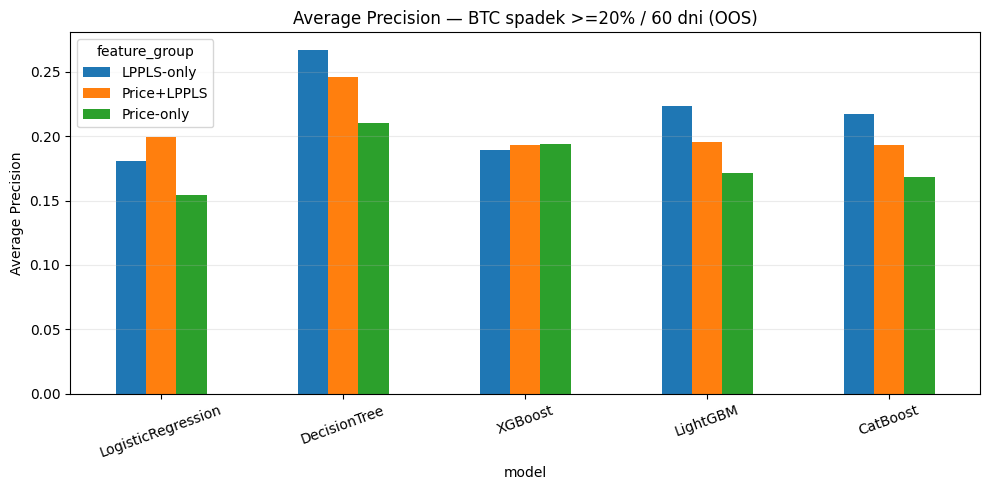

Wyniki: C:\Users\cynar\Desktop\projects\lppls_article\wyniki_tuning_08b


In [11]:
rows=[]
for (drop,horizon,name,group), part in preds.groupby(
    ['drop_pct','horizon','model','feature_group'],sort=False
):
    rows.append(dict(drop_pct=drop,horizon=horizon,model=name,feature_group=group,
                     **evaluate(part.y_true,part.y_pred,part.score)))
summary=pd.DataFrame(rows).sort_values(['drop_pct','horizon','feature_group','model'])
summary.to_csv(OUT/'08b_05_wyniki_laczne_OOS.csv',index=False)
for drop,horizon in TARGET_CONFIGS:
    s=summary.loc[(summary.drop_pct==drop)&(summary.horizon==horizon)]
    display(s[['model','feature_group','precision','recall','f1','specificity',
               'roc_auc','avg_precision','alarm_days','FP']].round(3))
    ml=s.loc[s.feature_group!='Baseline']
    pr=ml.loc[ml.feature_group=='Price-only'].set_index('model')
    hy=ml.loc[ml.feature_group=='Price+LPPLS'].set_index('model')
    delta=pd.DataFrame({'delta_F1':hy.f1-pr.f1,
        'delta_AvgPrecision':hy.avg_precision-pr.avg_precision,
        'delta_ROC_AUC':hy.roc_auc-pr.roc_auc}).reset_index()
    display(delta.round(3))
    delta.to_csv(OUT/f'08b_06_wartosc_dodana_LPPLS_{drop}_{horizon}.csv',index=False)
    piv=ml.pivot(index='model',columns='feature_group',values='avg_precision')
    piv=piv.reindex(MODEL_NAMES)
    ax=piv.plot.bar(figsize=(10,5),rot=20)
    ax.set_title(f'Average Precision — BTC spadek >={drop}% / {horizon} dni (OOS)')
    ax.set_ylabel('Average Precision')
    ax.grid(axis='y',alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUT/f'08b_07_AP_modele_{drop}_{horizon}.png',dpi=180)
    plt.show()

print('Wyniki:',OUT.resolve())